WatershedGrid(window=(6018, 5247), cells=13,631,535, area=11,873.1 km2, res=29.51 m)
dem_cropped.tif               139.5 MB
dem_conditioned.tif           674.5 MB
flow_direction.tif            168.7 MB
flow_accumulation.tif         337.3 MB

Basin cells with no flow direction (outlet / pits): 0  (expect a handful at most)


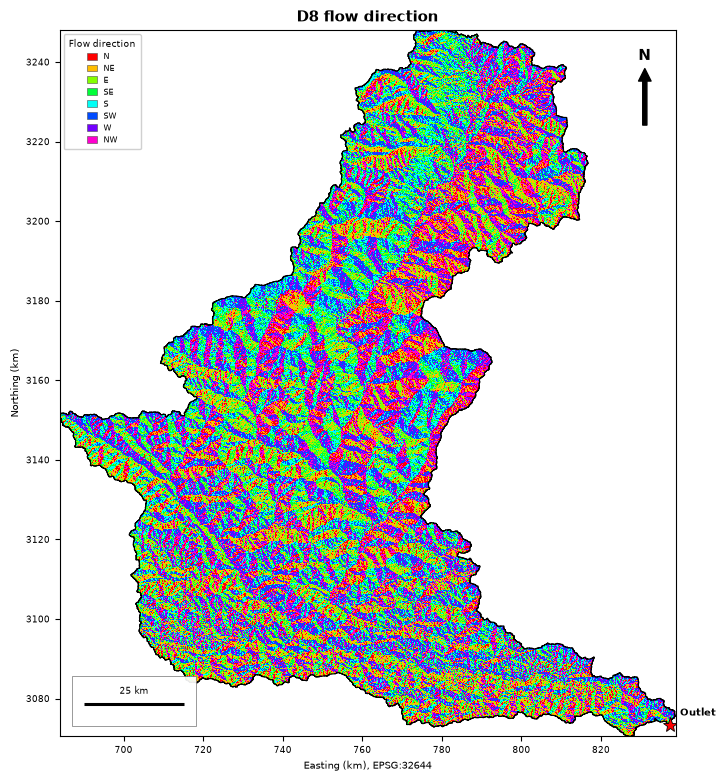

,class_id,label,cells,area_km2,percent
0,1,N,1385532,1206.80,10.16
1,2,NE,1854413,1615.20,13.60
2,3,E,1613468,1405.33,11.84
3,4,SE,1787557,1556.97,13.11
4,5,S,1614539,1406.27,11.84
5,6,SW,2004190,1745.65,14.70
6,7,W,1713177,1492.18,12.57
7,8,NW,1658659,1444.69,12.17



Max accumulation in basin: 13,631,535 cells = 11,873.1 km2
Basin cells              : 13,631,535
Outlet accumulation == basin cell count: True


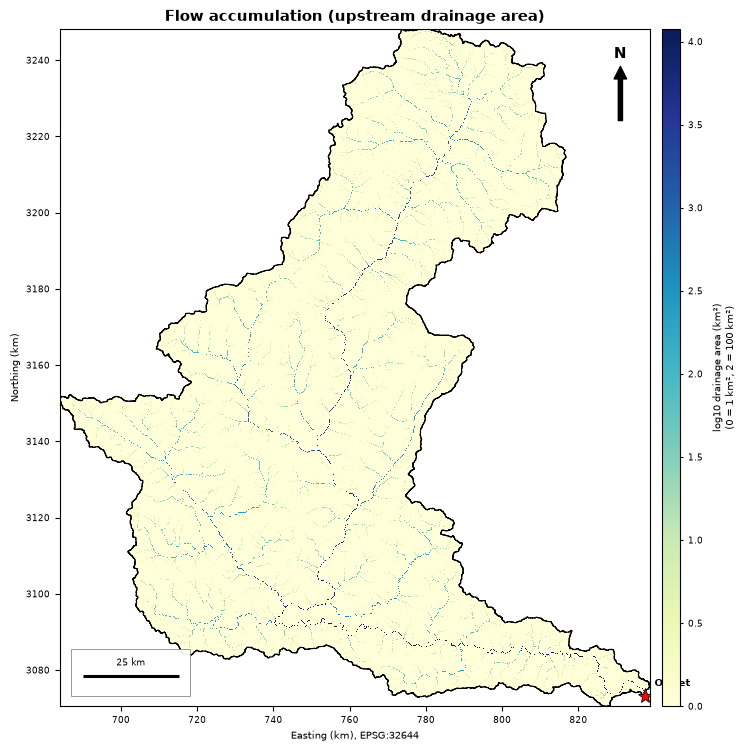

,metric,value
0,max_accumulation_cells,1.363154e+07
1,max_drainage_area_km2,1.187309e+04
2,basin_cells,1.363154e+07
3,pct_cells_area_ge_1_km2,1.715000e+00
4,pct_cells_area_ge_10_km2,6.120000e-01
5,pct_cells_area_ge_100_km2,2.220000e-01
6,pct_cells_area_ge_1000_km2,8.900000e-02


In [8]:
# ============================================================
# 03_Hydrology.ipynb | Cell 1: setup, D8 direction + flow accumulation
# ============================================================
import importlib
import numpy as np
import matplotlib.colors as mcolors
from whitebox import WhiteboxTools
import utils
importlib.reload(utils)
from utils import *

P = get_paths()
DEM_CROP = P.RAS / "dem_cropped.tif"
DEM_COND = P.RAS / "dem_conditioned.tif"
FDIR     = P.RAS / "flow_direction.tif"
FACC     = P.RAS / "flow_accumulation.tif"
TMP = P.RAS / "_tmp"
TMP.mkdir(exist_ok=True)

wbt = WhiteboxTools()
wbt.set_working_dir(str(TMP))
wbt.set_verbose_mode(False)

ws = WatershedGrid(P.RAS / "watershed_mask.tif",
                   P.VEC / "watershed_boundary.gpkg",
                   P.VEC / "outlet_snapped.shp")
print(ws)

for p in (DEM_CROP, DEM_COND, FDIR, FACC):
    assert p.exists(), f"missing input: {p}"
    print(f"{p.name:<26} {p.stat().st_size / 1e6:8.1f} MB")


def block_max(a, target=3000):
    """Down-sample by block maximum so thin river lines survive
    (plain subsampling drops most of them). Trims up to k-1 edge cells."""
    k = int(np.ceil(max(a.shape) / target))
    if k <= 1:
        return a
    h, w = (a.shape[0] // k) * k, (a.shape[1] // k) * k
    b = a[:h, :w].reshape(h // k, k, w // k, k)
    return np.fmax.reduce(np.fmax.reduce(b, axis=3), axis=1)


# ---------- 1) D8 flow direction, clipped and decoded ----------
fcode = ws.read(FDIR)                                     # whitebox codes 1..128
D8_TO_CLASS = {64: 1, 128: 2, 1: 3, 2: 4, 4: 5, 8: 6, 16: 7, 32: 8}
DIR_LABELS  = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
DIR_COLORS  = [mcolors.to_hex(plt.get_cmap("hsv")(i / 8)) for i in range(8)]

dir_cls = np.full(fcode.shape, np.nan, dtype="float32")
for code, cid in D8_TO_CLASS.items():
    dir_cls[fcode == code] = cid

n_nodir = int((ws.mask & ~np.isfinite(dir_cls)).sum())
print(f"\nBasin cells with no flow direction (outlet / pits): {n_nodir:,}  (expect a handful at most)")

ws.save(fcode,   P.RAS / "d8_direction_codes.tif",   nodata=0, dtype="uint8")
ws.save(dir_cls, P.RAS / "d8_direction_classes.tif", nodata=0, dtype="uint8")

make_map(dir_cls, ws, P.FIG / "03_d8_direction.png", title="D8 flow direction",
         label="Flow direction",
         classes=[(i + 1, DIR_LABELS[i], DIR_COLORS[i]) for i in range(8)])

tab_dir = class_table(dir_cls, DIR_LABELS, ws)
save_table(tab_dir, P.TAB / "03_d8_direction_classes.csv")
display(tab_dir)

# ---------- 2) flow accumulation, clipped ----------
acc_cells = ws.read(FACC)
acc_km2   = acc_cells * ws.cell_area_km2
ws.save(acc_km2, P.RAS / "flow_accumulation_km2.tif")

print(f"\nMax accumulation in basin: {np.nanmax(acc_cells):,.0f} cells "
      f"= {np.nanmax(acc_km2):,.1f} km2")
print(f"Basin cells              : {ws.n_cells:,}")
print(f"Outlet accumulation == basin cell count: {np.nanmax(acc_cells) == ws.n_cells}")

logA = np.log10(acc_km2)
make_map(block_max(logA), ws, P.FIG / "03_flow_accumulation.png",
         title="Flow accumulation (upstream drainage area)",
         label="log10 drainage area (km²)\n(0 = 1 km², 2 = 100 km²)",
         cmap="YlGnBu", vmin=0, vmax=float(np.nanmax(logA)))

# ---------- 3) summary table ----------
thr = [1, 10, 100, 1000]
valid = acc_km2[np.isfinite(acc_km2)]
acc_sum = pd.DataFrame({
    "metric": ["max_accumulation_cells", "max_drainage_area_km2", "basin_cells"]
              + [f"pct_cells_area_ge_{t}_km2" for t in thr],
    "value":  [np.nanmax(acc_cells), np.nanmax(acc_km2), ws.n_cells]
              + [100 * (valid >= t).mean() for t in thr]}).round(3)
save_table(acc_sum, P.TAB / "03_flow_accumulation_summary.csv")
display(acc_sum)

Downstream flow length         rc=0     3.3 s
Longest upstream flowpath      rc=0     4.8 s
D-inf specific catchment area  rc=0     6.2 s
downstream length  valid cells: 13,631,535 (basin: 13,631,535)
upstream length    valid cells: 13,631,535 (basin: 13,631,535)
SCA                valid cells: 13,631,535 (basin: 13,631,535)

Longest flowpath, from downstream-length raster : 422.3 km
Longest flowpath, from upstream-length raster   : 422.3 km (difference -0.0 %)
Flowpath source: x=773,557, y=3,247,822, elevation 6,148 m
Elevation drop along it: 5,964 m -> mean gradient 0.0141 m/m
Longest flowpath (vector)      rc=0     7.1 s
Vector length: 422.3 km | columns: ['FID', 'BASIN', 'UP_ELEV', 'DN_ELEV', 'LENGTH', 'AVG_SLOPE', 'geometry']


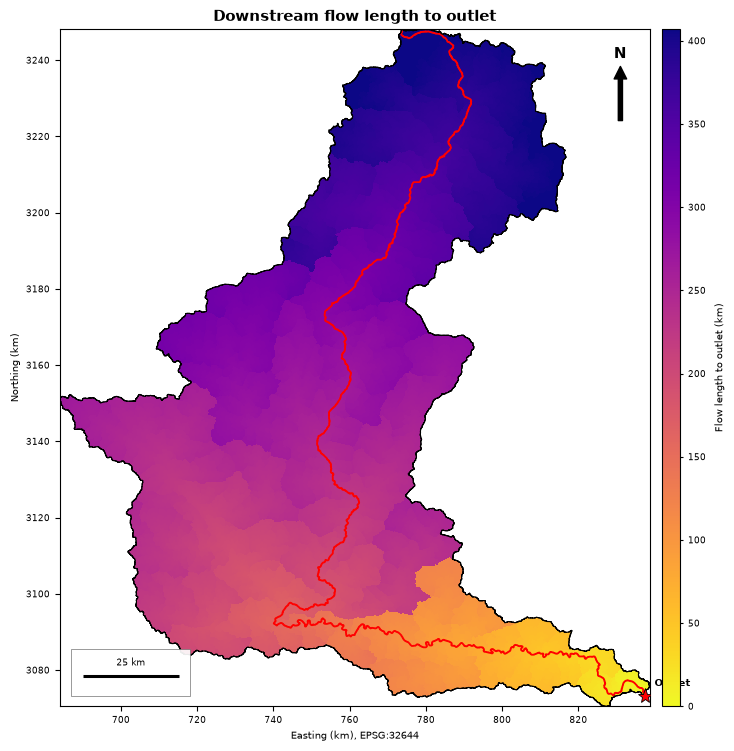

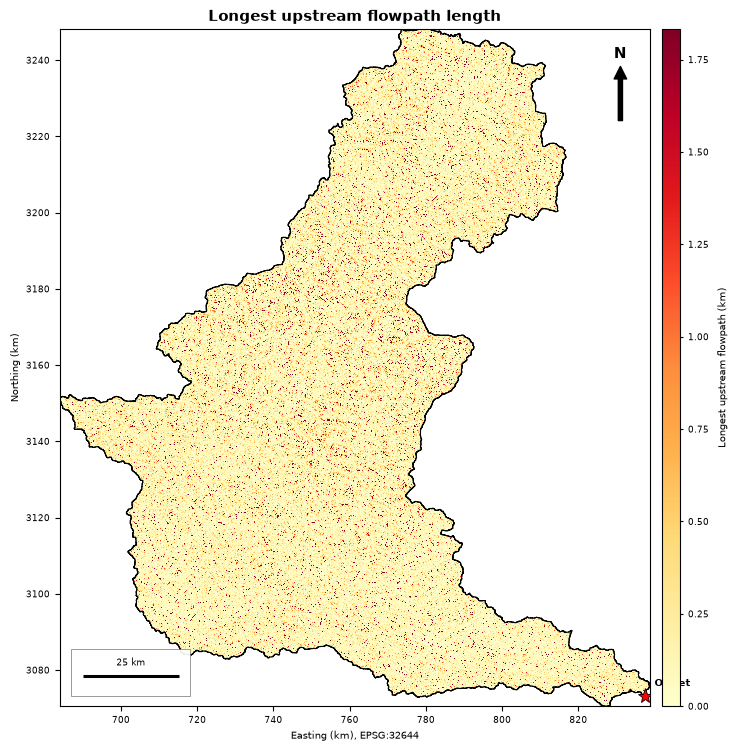

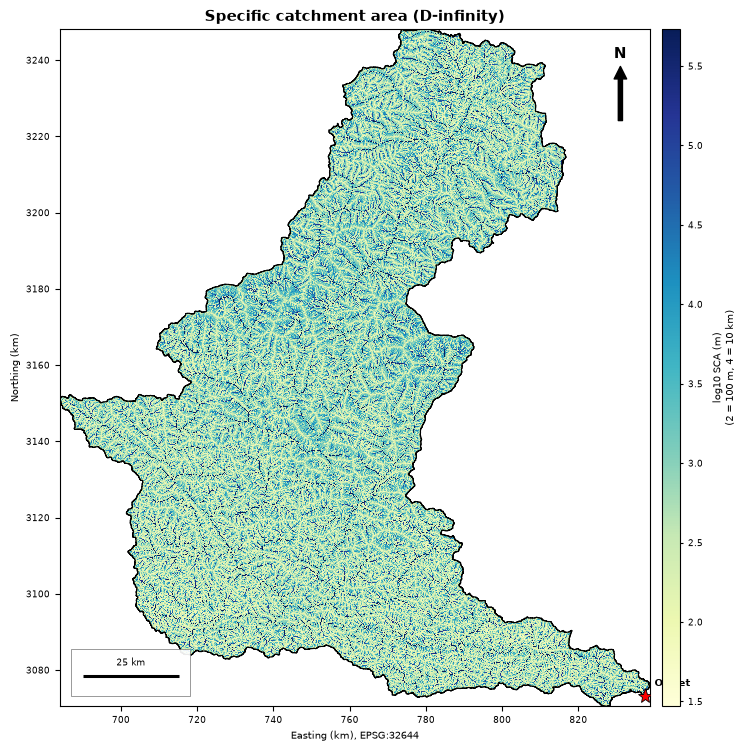

,layer,min,mean,median,p98,max
0,flow_length_downstream_m,29.51,260435.484375,257303.046875,406986.593750,4.223041e+05
1,flow_length_upstream_max_m,0.00,480.880005,71.250000,1835.209961,4.222746e+05
2,sca_dinf_m,29.51,218897.437500,136.570007,25184.099609,4.022960e+08


In [9]:
# ============================================================
# Cell 2: flow length (downstream, longest upstream) + D-inf specific catchment area
# ============================================================
import geopandas as gpd

WS_FULL    = P.RAS / "watershed_mask.tif"           # full-grid mask (1 inside basin)
L_DOWN_TMP = TMP / "flowlen_down_full.tif"
L_UP_TMP   = TMP / "flowlen_up_full.tif"
SCA_TMP    = TMP / "sca_dinf_full.tif"
LFP_SHP    = P.VEC / "longest_flowpath.shp"

# ---------- 1) whitebox on the full grid ----------
wbt_run("Downstream flow length", wbt.downslope_flowpath_length,
        str(FDIR), str(L_DOWN_TMP), watersheds=str(WS_FULL))
wbt_run("Longest upstream flowpath", wbt.max_upslope_flowpath_length,
        str(DEM_COND), str(L_UP_TMP))
wbt_run("D-inf specific catchment area", wbt.d_inf_flow_accumulation,
        str(DEM_COND), str(SCA_TMP), out_type="Specific Contributing Area")

# ---------- 2) clip to the watershed ----------
len_down = ws.read(L_DOWN_TMP)          # metres
len_up   = ws.read(L_UP_TMP)            # metres
sca      = ws.read(SCA_TMP)             # m2 per m of contour width, i.e. metres
dem      = ws.read(DEM_CROP)

for name, a in [("downstream length", len_down), ("upstream length", len_up), ("SCA", sca)]:
    print(f"{name:<18} valid cells: {np.isfinite(a).sum():,} (basin: {ws.n_cells:,})")

ws.save(len_down, P.RAS / "flow_length_downstream_m.tif")
ws.save(len_up,   P.RAS / "flow_length_upstream_max_m.tif")
ws.save(sca,      P.RAS / "sca_dinf_m.tif")

# ---------- 3) longest flowpath: numbers + cross-check ----------
L_down_km = np.nanmax(len_down) / 1000
L_up_km   = np.nanmax(len_up) / 1000
i = np.nanargmax(len_down)
r, c = np.unravel_index(i, len_down.shape)
src_x = ws.transform.c + (c + 0.5) * ws.transform.a
src_y = ws.transform.f + (r + 0.5) * ws.transform.e
drop = dem[r, c] - np.nanmin(dem)

print(f"\nLongest flowpath, from downstream-length raster : {L_down_km:,.1f} km")
print(f"Longest flowpath, from upstream-length raster   : {L_up_km:,.1f} km "
      f"(difference {100 * (L_up_km - L_down_km) / L_down_km:+.1f} %)")
print(f"Flowpath source: x={src_x:,.0f}, y={src_y:,.0f}, elevation {dem[r, c]:,.0f} m")
print(f"Elevation drop along it: {drop:,.0f} m -> mean gradient {drop / (L_down_km * 1000):.4f} m/m")

# ---------- 4) longest flowpath as a vector (skipped gracefully if the tool fails) ----------
lfp = None
try:
    wbt_run("Longest flowpath (vector)", wbt.longest_flowpath,
            str(DEM_COND), str(WS_FULL), str(LFP_SHP))
    lfp = gpd.read_file(LFP_SHP)
    if lfp.crs is None:
        lfp = lfp.set_crs(ws.crs)
    lfp.to_file(P.VEC / "longest_flowpath.gpkg", driver="GPKG")
    print(f"Vector length: {lfp.length.sum() / 1000:,.1f} km | columns: {list(lfp.columns)}")
except Exception as e:
    print("Longest-flowpath vector step failed, continuing without it:", e)

# ---------- 5) maps ----------
ov = dict(overlay=lfp, overlay_kw=dict(color="red", linewidth=1.3)) if lfp is not None else {}
make_map(len_down / 1000, ws, P.FIG / "03_flow_length_downstream.png",
         title="Downstream flow length to outlet",
         label="Flow length to outlet (km)", cmap="plasma_r", vmin=0, **ov)
make_map(len_up / 1000, ws, P.FIG / "03_flow_length_upstream.png",
         title="Longest upstream flowpath length",
         label="Longest upstream flowpath (km)", cmap="YlOrRd", vmin=0)

logS = np.log10(sca)
make_map(block_max(logS), ws, P.FIG / "03_sca_dinf.png",
         title="Specific catchment area (D-infinity)",
         label="log10 SCA (m)\n(2 = 100 m, 4 = 10 km)", cmap="YlGnBu",
         vmin=float(np.nanpercentile(logS, 2)), vmax=float(np.nanpercentile(logS, 99.5)))

# ---------- 6) statistics ----------
rows = []
for name, a in [("flow_length_downstream_m", len_down), ("flow_length_upstream_max_m", len_up),
                ("sca_dinf_m", sca)]:
    v = a[np.isfinite(a)]
    rows.append(dict(layer=name, min=v.min(), mean=v.mean(), median=np.median(v),
                     p98=np.percentile(v, 98), max=v.max()))
flow_stats = pd.DataFrame(rows).round(2)
save_table(flow_stats, P.TAB / "03_flow_length_sca_statistics.csv")
display(flow_stats)

Slope on conditioned DEM       rc=0     2.2 s
Mean slope, conditioned DEM : 28.17 deg
Mean slope, original DEM    : 28.15 deg
Cells at the 0.1 deg slope floor: 0.00 %
TWI: valid cells 13,631,535 (basin: 13,631,535)
SPI: valid cells 13,631,535 (basin: 13,631,535)
STI: valid cells 13,631,535 (basin: 13,631,535)


,class_id,label,cells,area_km2,percent,twi_from,twi_to
0,1,Very dry (1.1 to 4.6),2726304,2374.62,20.0,1.097,4.643
1,2,Dry (4.6 to 5.3),2726309,2374.62,20.0,4.643,5.250
2,3,Moderate (5.3 to 5.9),2726307,2374.62,20.0,5.250,5.931
3,4,Wet (5.9 to 7.0),2726308,2374.62,20.0,5.931,7.010
4,5,Very wet (7.0 to 26.2),2726307,2374.62,20.0,7.010,26.157


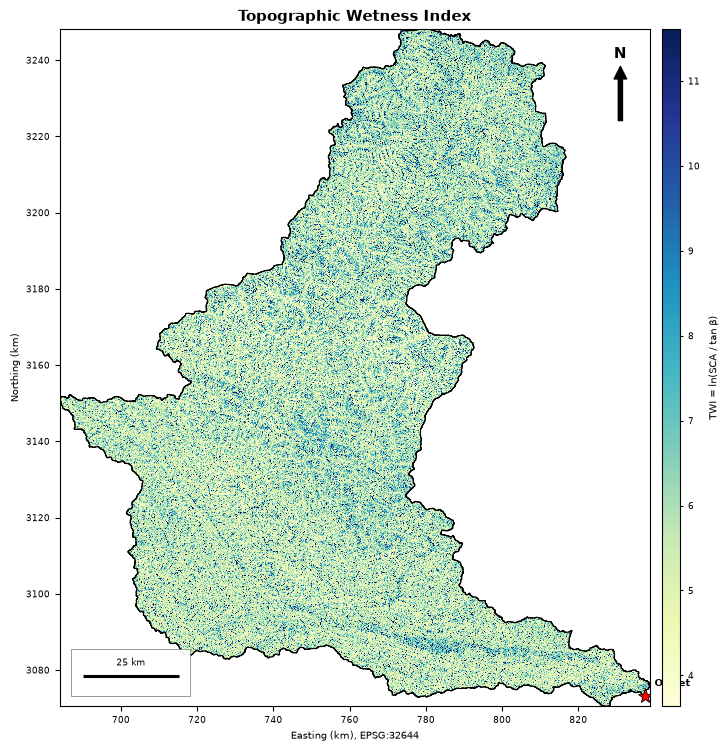

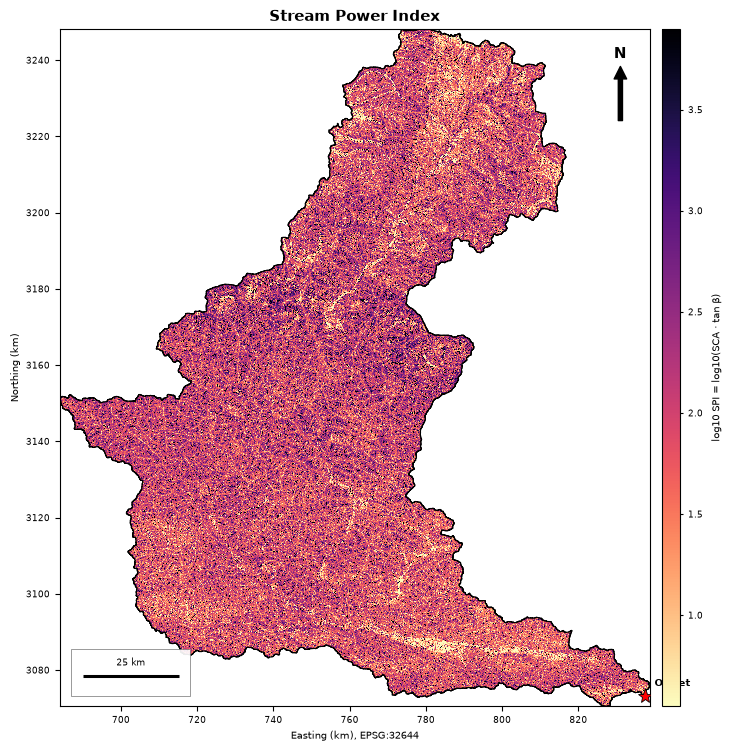

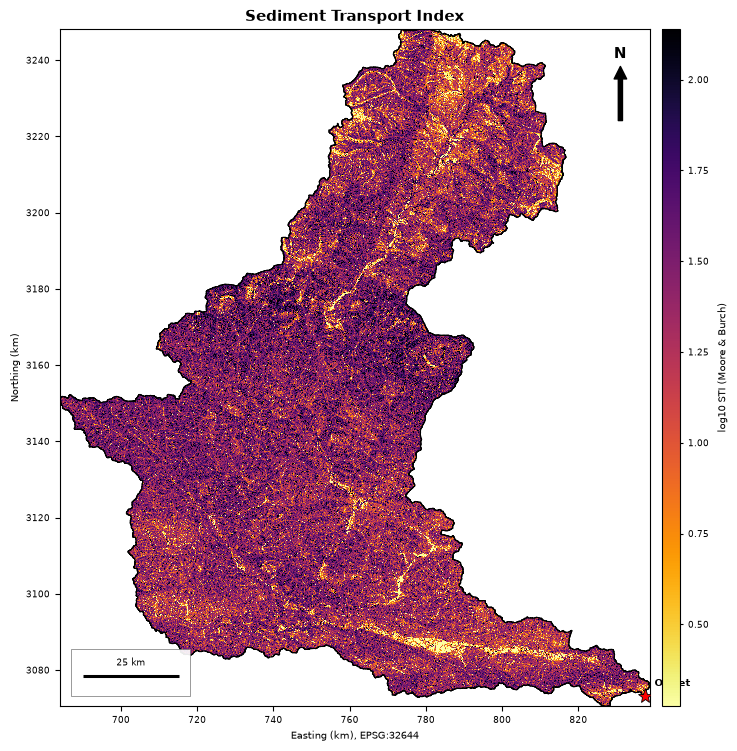

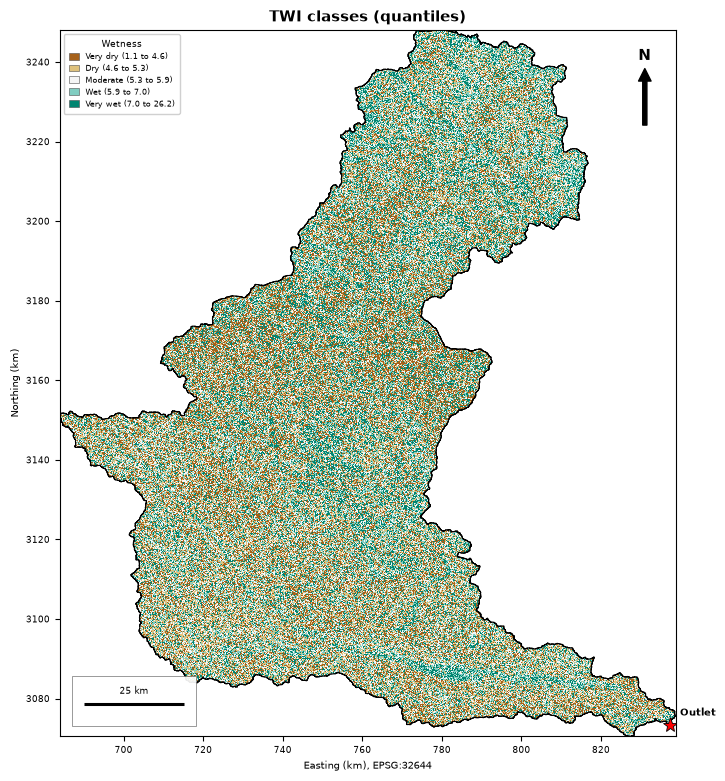

,layer,min,p2,mean,median,p98,max
0,twi,1.0966,3.6353,6.005100,5.568200,11.612200,2.615690e+01
1,spi,0.0515,3.5641,26856.537109,80.895103,7900.354980,5.759052e+08
2,sti,0.0094,1.8889,36.749699,26.591700,137.868393,1.918759e+04
3,slope_hydrologic_deg,0.0000,4.1625,28.173401,27.957701,55.797798,8.485870e+01


TWI class polygons: 5 features (100 s)


In [10]:
# ============================================================
# Cell 3: hydrologic slope, TWI, SPI, STI (+ TWI classes)
# ============================================================
# ---------- parameters ----------
SLOPE_FLOOR_DEG = 0.1                    # avoids division by zero on flat cells
STI_M, STI_N    = 0.4, 1.3               # Moore & Burch (1991)
TWI_QUANTILES   = [0.2, 0.4, 0.6, 0.8]
TWI_NAMES  = ["Very dry", "Dry", "Moderate", "Wet", "Very wet"]
TWI_COLORS = ["#a6611a", "#dfc27d", "#f5f5f5", "#80cdc1", "#018571"]


def read_clipped(path):
    """Read a raster that is already on the clipped basin grid."""
    with rasterio.open(path) as s:
        a = s.read(1).astype("float32")
        nd = s.nodata
    if nd is not None:
        a[a == nd] = np.nan
    return a


if "sca" not in globals():               # kernel restarted since Cell 2
    sca = read_clipped(P.RAS / "sca_dinf_m.tif")

# ---------- 1) hydrologic slope (conditioned DEM) ----------
SLOPE_H_TMP = TMP / "slope_hydro_full.tif"
wbt_run("Slope on conditioned DEM", wbt.slope, str(DEM_COND), str(SLOPE_H_TMP), units="degrees")
slope_h = ws.read(SLOPE_H_TMP)
ws.save(slope_h, P.RAS / "slope_hydrologic_deg.tif")

slope_t = read_clipped(P.RAS / "slope_deg.tif")          # terrain slope from notebook 02
print(f"Mean slope, conditioned DEM : {np.nanmean(slope_h):.2f} deg")
print(f"Mean slope, original DEM    : {np.nanmean(slope_t):.2f} deg")
print(f"Cells at the {SLOPE_FLOOR_DEG} deg slope floor: "
      f"{100 * np.nanmean(slope_h < SLOPE_FLOOR_DEG):.2f} %")

# ---------- 2) indices ----------
beta = np.deg2rad(np.maximum(slope_h, SLOPE_FLOOR_DEG))
tanb, sinb = np.tan(beta), np.sin(beta)
twi = np.log(sca / tanb)
spi = sca * tanb
sti = (STI_M + 1) * (sca / 22.13) ** STI_M * (sinb / 0.0896) ** STI_N
del beta, tanb, sinb

for name, a in [("TWI", twi), ("SPI", spi), ("STI", sti)]:
    print(f"{name}: valid cells {np.isfinite(a).sum():,} (basin: {ws.n_cells:,})")

ws.save(twi, P.RAS / "twi.tif")
ws.save(spi, P.RAS / "spi.tif")
ws.save(sti, P.RAS / "sti.tif")

# ---------- 3) TWI classes (quantiles) ----------
valid = twi[np.isfinite(twi)]
breaks = np.quantile(valid, TWI_QUANTILES)
edges = np.concatenate([[valid.min()], breaks, [valid.max()]])
twi_cls = classify(twi, breaks)
TWI_LABELS = [f"{TWI_NAMES[i]} ({edges[i]:.1f} to {edges[i + 1]:.1f})" for i in range(5)]
ws.save(twi_cls, P.RAS / "twi_classes.tif", nodata=0, dtype="uint8")

tab_twi = class_table(twi_cls, TWI_LABELS, ws)
tab_twi["twi_from"] = edges[:-1].round(3)
tab_twi["twi_to"] = edges[1:].round(3)
save_table(tab_twi, P.TAB / "03_twi_classes.csv")
display(tab_twi)

# ---------- 4) maps ----------
make_map(twi, ws, P.FIG / "03_twi.png", title="Topographic Wetness Index",
         label="TWI = ln(SCA / tan β)", cmap="YlGnBu")
make_map(np.log10(spi), ws, P.FIG / "03_spi.png", title="Stream Power Index",
         label="log10 SPI = log10(SCA · tan β)", cmap="magma_r")
make_map(np.log10(sti), ws, P.FIG / "03_sti.png", title="Sediment Transport Index",
         label="log10 STI (Moore & Burch)", cmap="inferno_r")
make_map(twi_cls, ws, P.FIG / "03_twi_classes.png", title="TWI classes (quantiles)",
         label="Wetness", classes=[(i + 1, TWI_LABELS[i], TWI_COLORS[i]) for i in range(5)])

# ---------- 5) statistics ----------
rows = []
for name, a in [("twi", twi), ("spi", spi), ("sti", sti), ("slope_hydrologic_deg", slope_h)]:
    v = a[np.isfinite(a)]
    rows.append(dict(layer=name, min=v.min(), p2=np.percentile(v, 2), mean=v.mean(),
                     median=np.median(v), p98=np.percentile(v, 98), max=v.max()))
idx_stats = pd.DataFrame(rows).round(4)
save_table(idx_stats, P.TAB / "03_index_statistics.csv")
display(idx_stats)

# ---------- 6) vector: TWI class polygons ----------
t0 = time.time()
g_twi = classes_to_vector(twi_cls, ws, TWI_LABELS, P.VEC / "twi_classes", sieve_px=100)
print(f"TWI class polygons: {len(g_twi)} features ({time.time() - t0:.0f} s)")

Cells changed      : 96,400 (0.71 % of basin)
  lowered (breach) : 66,558 | mean -8.17 m | max -460.0 m
  raised (fill)    : 29,842 | mean 2.20 m | max 169.0 m
Net volume change  : -416.48 million m3


,change_magnitude,lowered_cells,raised_cells,lowered_pct_basin,raised_pct_basin
0,<1 m,12500,15841,0.092,0.116
1,1-5 m,31362,12328,0.230,0.090
2,5-20 m,17773,1597,0.130,0.012
3,20-50 m,3171,68,0.023,0.000
4,>50 m,1752,8,0.013,0.000


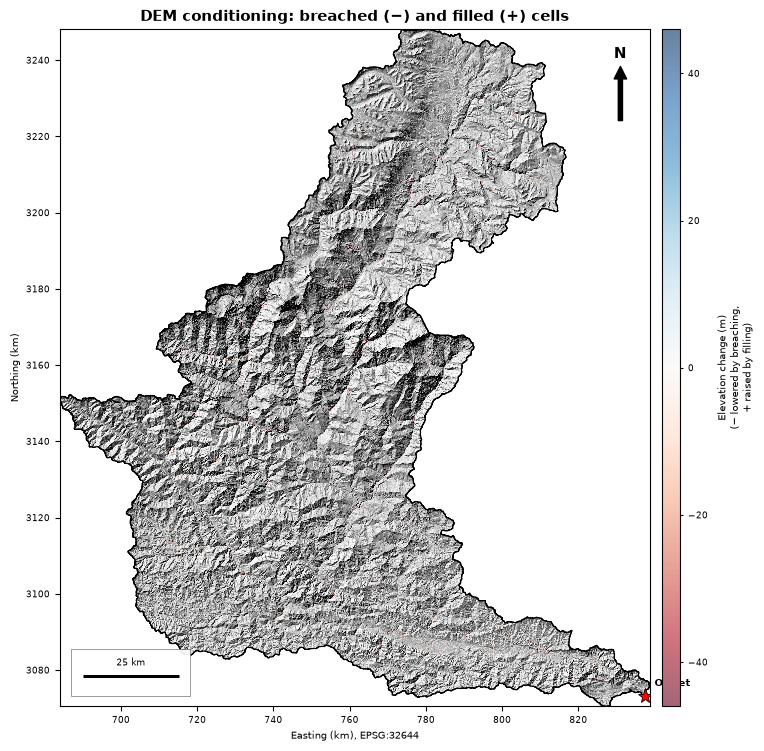

,metric,value
0,basin_area_km2,11873.0888
1,longest_flowpath_km,422.2746
2,flowpath_source_elev_m,6148.0000
3,flowpath_outlet_elev_m,184.0000
4,flowpath_mean_gradient_m_per_m,0.0141
5,cells_changed_by_conditioning_pct,0.7072
6,net_volume_change_million_m3,-416.4788



file                                exists        MB
d8_direction_codes.tif              True         3.8
d8_direction_classes.tif            True         3.8
flow_accumulation_km2.tif           True        17.2
flow_length_downstream_m.tif        True        42.8
flow_length_upstream_max_m.tif      True        21.4
sca_dinf_m.tif                      True        58.3
slope_hydrologic_deg.tif            True        61.7
twi.tif                             True        60.2
spi.tif                             True        66.5
sti.tif                             True        63.7
twi_classes.tif                     True         4.2
breach_difference_m.tif             True         1.2
longest_flowpath.gpkg               True         0.2
longest_flowpath.shp                True         0.1
twi_classes.gpkg                    True       288.0
twi_classes.shp                     True       267.5
03_breach_difference.png            True         2.8
03_conditioning_hotspot_zoom.png    True     

In [11]:
# ============================================================
# Cell 4: conditioning difference (breach / fill), hydrology summary, output inventory
# ============================================================
TOL = 0.001      # m; changes smaller than this count as unchanged


def block_absmax(a, target=3000):
    """Down-sample a signed array, keeping the largest-magnitude value in each block
    (so thin breach lines survive)."""
    k = int(np.ceil(max(a.shape) / target))
    if k <= 1:
        return a
    h, w = (a.shape[0] // k) * k, (a.shape[1] // k) * k
    b = a[:h, :w].reshape(h // k, k, w // k, k)
    mn = np.fmin.reduce(np.fmin.reduce(b, axis=3), axis=1)
    mx = np.fmax.reduce(np.fmax.reduce(b, axis=3), axis=1)
    return np.where(np.abs(mn) >= np.abs(mx), mn, mx)


# ---------- 1) conditioned minus original cropped DEM ----------
dem_orig = ws.read(DEM_CROP)
dem_cond = ws.read(DEM_COND)
diff = dem_cond - dem_orig
diff[np.abs(diff) < TOL] = 0
ws.save(diff, P.RAS / "breach_difference_m.tif")

d = diff[np.isfinite(diff)]
lowered, raised = d[d < 0], d[d > 0]
cell_m2 = ws.res[0] * ws.res[1]
print(f"Cells changed      : {len(lowered) + len(raised):,} "
      f"({100 * (len(lowered) + len(raised)) / ws.n_cells:.2f} % of basin)")
print(f"  lowered (breach) : {len(lowered):,} | mean {lowered.mean():.2f} m | max {lowered.min():.1f} m")
print(f"  raised (fill)    : {len(raised):,} | mean {raised.mean():.2f} m | max {raised.max():.1f} m")
print(f"Net volume change  : {d.sum() * cell_m2 / 1e6:,.2f} million m3")

bins = [1, 5, 20, 50]
labels = ["<1 m", "1-5 m", "5-20 m", "20-50 m", ">50 m"]
cnt = lambda x: np.bincount(np.digitize(np.abs(x), bins), minlength=len(labels))
tab_breach = pd.DataFrame({"change_magnitude": labels,
                           "lowered_cells": cnt(lowered), "raised_cells": cnt(raised)})
tab_breach["lowered_pct_basin"] = (100 * tab_breach.lowered_cells / ws.n_cells).round(3)
tab_breach["raised_pct_basin"]  = (100 * tab_breach.raised_cells / ws.n_cells).round(3)
save_table(tab_breach, P.TAB / "03_breach_difference_classes.csv")
display(tab_breach)

# ---------- 2) map over hillshade ----------
with rasterio.open(P.RAS / "hillshade.tif") as s:
    hs_clip = s.read(1).astype("float32")
    nd = s.nodata
if nd is not None:
    hs_clip[hs_clip == nd] = np.nan

plot = np.where(diff == 0, np.nan, diff)
nz = np.abs(d[d != 0])
lim = float(np.percentile(nz, 98)) if nz.size else 1.0
make_map(block_absmax(plot), ws, P.FIG / "03_breach_difference.png",
         title="DEM conditioning: breached (−) and filled (+) cells",
         label="Elevation change (m)\n(− lowered by breaching,\n+ raised by filling)",
         cmap="RdBu", vmin=-lim, vmax=lim, hillshade=hs_clip)

# ---------- 3) hydrology summary (values reused later in the statistics notebook) ----------
lfp = gpd.read_file(P.VEC / "longest_flowpath.gpkg")
L_km = lfp.length.sum() / 1000
up_e, dn_e = float(lfp["UP_ELEV"].iloc[0]), float(lfp["DN_ELEV"].iloc[0])
hyd = pd.DataFrame({
    "metric": ["basin_area_km2", "longest_flowpath_km", "flowpath_source_elev_m",
               "flowpath_outlet_elev_m", "flowpath_mean_gradient_m_per_m",
               "cells_changed_by_conditioning_pct", "net_volume_change_million_m3"],
    "value": [ws.area_km2, L_km, up_e, dn_e, (up_e - dn_e) / (L_km * 1000),
              100 * (len(lowered) + len(raised)) / ws.n_cells, d.sum() * cell_m2 / 1e6]}).round(4)
save_table(hyd, P.TAB / "03_hydrology_summary.csv")
display(hyd)

# ---------- 4) output inventory ----------
expected = {
    P.RAS: ["d8_direction_codes.tif", "d8_direction_classes.tif", "flow_accumulation_km2.tif",
            "flow_length_downstream_m.tif", "flow_length_upstream_max_m.tif", "sca_dinf_m.tif",
            "slope_hydrologic_deg.tif", "twi.tif", "spi.tif", "sti.tif", "twi_classes.tif",
            "breach_difference_m.tif"],
    P.VEC: ["longest_flowpath.gpkg", "longest_flowpath.shp", "twi_classes.gpkg", "twi_classes.shp"],
}
print(f"\n{'file':<36}{'exists':<8}{'MB':>8}")
for folder, names in expected.items():
    for n in names:
        p = folder / n
        print(f"{n:<36}{str(p.exists()):<8}{(p.stat().st_size / 1e6 if p.exists() else 0):>8.1f}")
for folder in (P.FIG, P.TAB):
    for p in sorted(folder.glob("03_*")):
        print(f"{p.name:<36}{'True':<8}{p.stat().st_size / 1e6:>8.1f}")

tmp_mb = sum(p.stat().st_size for p in TMP.glob("*") if p.is_file()) / 1e6
print(f"\n_tmp holds {tmp_mb:,.0f} MB of scratch rasters (notebook 04 does not need them).")
# import shutil; shutil.rmtree(TMP, ignore_errors=True); TMP.mkdir(exist_ok=True)   # optional cleanup

In [12]:
# ============================================================
# Cell 5: where did conditioning change the DEM the most?
# ============================================================
from scipy import ndimage
from pyproj import Transformer

MIN_CHANGE = 20                                    # m
to_ll = Transformer.from_crs(ws.crs, 4326, always_xy=True)
dabs = np.abs(np.nan_to_num(diff))
elev0 = np.nan_to_num(dem_orig)

def cluster_table(mask, kind):
    lab, n = ndimage.label(mask)
    if n == 0:
        return pd.DataFrame()
    idx = np.arange(1, n + 1)
    cells = ndimage.sum(mask, lab, idx)
    dsum  = ndimage.sum(dabs, lab, idx)
    dmax  = ndimage.maximum(dabs, lab, idx)
    elev  = ndimage.mean(elev0, lab, idx)
    com   = np.array(ndimage.center_of_mass(mask, lab, idx))
    x = ws.transform.c + (com[:, 1] + 0.5) * ws.transform.a
    y = ws.transform.f + (com[:, 0] + 0.5) * ws.transform.e
    lon, lat = to_ll.transform(x, y)
    t = pd.DataFrame({"kind": kind, "cells": cells.astype(int),
                      "area_km2": cells * ws.cell_area_km2,
                      "mean_change_m": dsum / cells, "max_change_m": dmax,
                      "volume_million_m3": dsum * cell_m2 / 1e6,
                      "mean_elev_m": elev, "lon": lon, "lat": lat})
    return t.sort_values("volume_million_m3", ascending=False).reset_index(drop=True)

fills   = cluster_table(diff >  MIN_CHANGE, "fill")
breachs = cluster_table(diff < -MIN_CHANGE, "breach")
print(f"Fill clusters > {MIN_CHANGE} m: {len(fills):,} | breach clusters: {len(breachs):,}")
print(f"Top 10 fill clusters hold {100 * fills.volume_million_m3.head(10).sum() / fills.volume_million_m3.sum():.0f} % of fill volume")

hot = pd.concat([fills.head(10), breachs.head(10)]).round(3)
save_table(hot, P.TAB / "03_conditioning_hotspots.csv")
display(hot)

Fill clusters > 20 m: 76 | breach clusters: 2,454
Top 10 fill clusters hold 30 % of fill volume


,kind,cells,area_km2,mean_change_m,max_change_m,volume_million_m3,mean_elev_m,lon,lat
0,fill,1,0.001,169.000,169.000000,0.147,5707.000,83.726,29.204
1,fill,1,0.001,149.000,149.000000,0.130,2392.000,83.614,28.689
2,fill,1,0.001,89.000,89.000000,0.078,3450.000,83.906,28.512
3,fill,1,0.001,70.000,70.000000,0.061,3445.000,83.668,28.907
4,fill,1,0.001,62.000,62.000000,0.054,2435.000,83.613,28.689
5,fill,1,0.001,61.000,61.000000,0.053,3568.000,83.837,28.465
6,fill,1,0.001,57.000,57.000000,0.050,1597.000,83.590,28.143
7,fill,1,0.001,51.000,51.000000,0.044,1188.000,83.404,28.398
8,fill,1,0.001,50.000,50.000000,0.044,2501.000,83.874,28.477
9,fill,1,0.001,49.000,49.000000,0.043,3402.000,83.614,28.738


Cluster centre: 83.7262 E, 29.2042 N
Size          : 1 cells = 0.0 km2
Original DEM  : min 5,707 | mean 5,707 | max 5,707 m
Conditioned   : min 5,876 | median 5,876 | max 5,876 m (spread 0.0 m; near 0 = flat, lake-like surface)
Deepest fill  : 169 m
Touches the watershed boundary: False


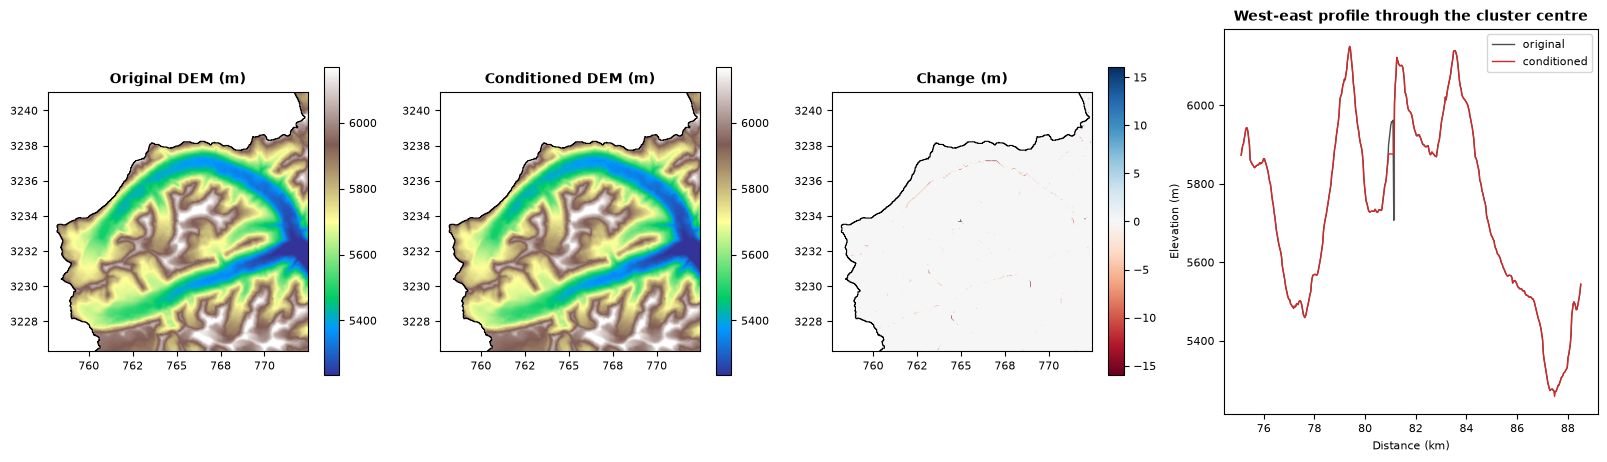

In [13]:
# ============================================================
# Cell 6: zoom on the largest conditioning fill
# ============================================================
lab, n = ndimage.label(diff > MIN_CHANGE)
vol = ndimage.sum(dabs, lab, np.arange(1, n + 1))
k = int(np.argmax(vol)) + 1
sl = ndimage.find_objects(lab)[k - 1]
inside = lab == k
del lab

o, c_ = dem_orig[inside], dem_cond[inside]
cr, cc = (sl[0].start + sl[0].stop) // 2, (sl[1].start + sl[1].stop) // 2
cx = ws.transform.c + (cc + 0.5) * ws.transform.a
cy = ws.transform.f + (cr + 0.5) * ws.transform.e
lon, lat = to_ll.transform(cx, cy)
touch = bool((ndimage.binary_dilation(inside, iterations=2) & ~ws.mask).any())

print(f"Cluster centre: {lon:.4f} E, {lat:.4f} N")
print(f"Size          : {inside.sum():,} cells = {inside.sum() * ws.cell_area_km2:.1f} km2")
print(f"Original DEM  : min {o.min():,.0f} | mean {o.mean():,.0f} | max {o.max():,.0f} m")
print(f"Conditioned   : min {c_.min():,.0f} | median {np.median(c_):,.0f} | max {c_.max():,.0f} m "
      f"(spread {c_.max() - c_.min():.1f} m; near 0 = flat, lake-like surface)")
print(f"Deepest fill  : {(c_ - o).max():,.0f} m")
print(f"Touches the watershed boundary: {touch}")

pad = 250                                               # cells around the cluster (~7 km)
r0, r1 = max(sl[0].start - pad, 0), min(sl[0].stop + pad, diff.shape[0])
c0, c1 = max(sl[1].start - pad, 0), min(sl[1].stop + pad, diff.shape[1])
ext = (ws.transform.c + c0 * ws.transform.a, ws.transform.c + c1 * ws.transform.a,
       ws.transform.f + r1 * ws.transform.e, ws.transform.f + r0 * ws.transform.e)
sub = lambda a: a[r0:r1, c0:c1]
lo, hi = np.nanpercentile(sub(dem_orig), 1), np.nanpercentile(sub(dem_orig), 99)
dl = float(np.nanpercentile(np.abs(sub(diff)[sub(diff) != 0]), 98))
km = FuncFormatter(lambda v, _: f"{v / 1000:.0f}")

fig, axs = plt.subplots(1, 4, figsize=(20, 5), gridspec_kw={"width_ratios": [1, 1, 1, 1.15]})
for ax, a, ttl, cm, v0, v1 in [(axs[0], sub(dem_orig), "Original DEM (m)", "terrain", lo, hi),
                               (axs[1], sub(dem_cond), "Conditioned DEM (m)", "terrain", lo, hi),
                               (axs[2], sub(diff), "Change (m)", "RdBu", -dl, dl)]:
    im = ax.imshow(a, extent=ext, cmap=cm, vmin=v0, vmax=v1)
    ws.boundary.boundary.plot(ax=ax, color="k", lw=0.8)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    ax.xaxis.set_major_formatter(km); ax.yaxis.set_major_formatter(km)
    ax.set_title(ttl, fontsize=10, fontweight="bold")
    fig.colorbar(im, ax=ax, shrink=0.8)

x_km = np.arange(c0, c1) * ws.res[0] / 1000
axs[3].plot(x_km, dem_orig[cr, c0:c1], color="0.3", lw=1, label="original")
axs[3].plot(x_km, dem_cond[cr, c0:c1], color="tab:red", lw=1, label="conditioned")
axs[3].fill_between(x_km, dem_orig[cr, c0:c1], dem_cond[cr, c0:c1],
                    where=dem_cond[cr, c0:c1] > dem_orig[cr, c0:c1], color="tab:red", alpha=0.25)
axs[3].set_title("West-east profile through the cluster centre", fontsize=10, fontweight="bold")
axs[3].set_xlabel("Distance (km)"); axs[3].set_ylabel("Elevation (m)"); axs[3].legend()
fig.savefig(P.FIG / "03_conditioning_hotspot_zoom.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

In [7]:
# ============================================================
# Cell 7: test - does a longer breach reach remove the giant fill?
# ============================================================
DIST_TEST = 250                                        # cells (about 7.4 km)
TEST = TMP / f"dem_cond_dist{DIST_TEST}.tif"
wbt_run(f"Breach, dist={DIST_TEST}", wbt.breach_depressions_least_cost,
        str(DEM_CROP), str(TEST), dist=DIST_TEST, fill=True)

d2 = ws.read(TEST) - dem_orig
d2[np.abs(d2) < TOL] = 0

def summary(dd, label):
    fl, br = dd > 0, dd < 0
    print(f"{label:<10} filled {fl.sum():>8,} cells, {np.nansum(dd[fl]) * cell_m2 / 1e6:>8,.0f} million m3"
          f" | breached {br.sum():>7,} cells, {-np.nansum(dd[br]) * cell_m2 / 1e6:>6,.0f} million m3")

summary(diff, "dist=100")
summary(d2,   f"dist={DIST_TEST}")

win = (slice(r0, r1), slice(c0, c1))
still = int((d2[inside] > MIN_CHANGE).sum())
cut = d2[win] < -MIN_CHANGE
print(f"\nGiant cluster cells still raised > {MIN_CHANGE} m: {still:,} of {inside.sum():,}")
print(f"Breached cells > {MIN_CHANGE} m in the zoom window: {cut.sum():,} "
      f"(deepest {np.nanmin(d2[win]):.0f} m)")

Breach, dist=250               rc=0    14.6 s
dist=100   filled   97,137 cells,    5,892 million m3 | breached  63,176 cells,    422 million m3
dist=250   filled   29,815 cells,       57 million m3 | breached  66,814 cells,    474 million m3

Giant cluster cells still raised > 20 m: 0 of 48,120
Breached cells > 20 m in the zoom window: 881 (deepest -425 m)
